Cell 1: Environment Setup & Library **Imports** **bold text**

In [ ]:
# ==============================================================================
# CELL 1: Environment Setup, Google Drive Mount & Library Imports
# ==============================================================================
from google.colab import drive
drive.mount('/content/drive')
print("Google Drive Mounted Successfully!")

!pip install -q xgboost imbalanced-learn cryptography pandas numpy scikit-learn matplotlib seaborn shap

import pandas as pd
import numpy as np
import time
import hashlib
import json
import gc
from cryptography.fernet import Fernet

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from xgboost import XGBClassifier

import shap
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
print("Cell 1 Execution Complete: All Advanced Libraries Imported.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive Mounted Successfully!
Cell 1 Execution Complete: All Advanced Libraries Imported.


Cell 2: Advanced Feature Engineering & Pre-Processing

In [ ]:
# ==============================================================================
# CELL 2: Data Loading & Advanced Feature Engineering (No SMOTE, No Distance)
# ==============================================================================
def advanced_preprocessing(train_path, test_path):
    print("Loading datasets (Using 100% Data)...")
    df_train = pd.read_csv(train_path)
    df_test = pd.read_csv(test_path)

    print("Engineering Temporal & Cyclic Features...")
    for df in [df_train, df_test]:
        dt = pd.to_datetime(df['trans_date_trans_time'])
        df['hour'] = dt.dt.hour
        df['dayofweek'] = dt.dt.dayofweek

        # Cyclic Encoding for Time (Better for Tree Models)
        df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
        df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)
        df['dow_sin'] = np.sin(2 * np.pi * df['dayofweek'] / 7)
        df['dow_cos'] = np.cos(2 * np.pi * df['dayofweek'] / 7)

        # Age & Amount features
        dob = pd.to_datetime(df['dob'])
        df['customer_age'] = (dt - dob).dt.days / 365.25
        df['amount_log'] = np.log1p(df['amt'])

    print("Applying Frequency Encoding...")
    cat_cols = ['merchant', 'category', 'city', 'state', 'job', 'gender']
    for col in cat_cols:
        freq_map = df_train[col].value_counts(normalize=True).to_dict()
        df_train[col + '_freq'] = df_train[col].map(freq_map).fillna(0)
        df_test[col + '_freq'] = df_test[col].map(freq_map).fillna(0)

    # Capture raw test snapshot for Live Simulator BEFORE dropping columns
    df_test_raw = df_test.copy()

    print("Dropping Irrelevant & Spatial Columns...")
    cols_to_drop = ['Unnamed: 0', 'trans_date_trans_time', 'cc_num', 'trans_num', 'first', 'last',
                    'street', 'city', 'state', 'zip', 'dob', 'job', 'merchant', 'category', 'gender',
                    'lat', 'long', 'merch_lat', 'merch_long'] # Distance/Coordinates completely removed

    X_train_raw = df_train.drop(columns=[c for c in cols_to_drop if c in df_train.columns] + ['is_fraud'])
    y_train = df_train['is_fraud']
    X_test_raw = df_test.drop(columns=[c for c in cols_to_drop if c in df_test.columns] + ['is_fraud'])
    y_test = df_test['is_fraud']

    # Fill missing values with median
    train_medians = X_train_raw.median(numeric_only=True)
    X_train_raw = X_train_raw.fillna(train_medians)
    X_test_raw = X_test_raw.fillna(train_medians)

    print("Scaling Features...")
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_raw), columns=X_train_raw.columns)
    X_test_scaled = pd.DataFrame(scaler.transform(X_test_raw), columns=X_test_raw.columns)

    print("Creating Validation Split (80/20)...")
    X_fit, X_val, y_fit, y_val = train_test_split(X_train_scaled, y_train, test_size=0.20, stratify=y_train, random_state=42)

    # Calculate Class Imbalance Weight (Instead of SMOTE)
    neg_samples = (y_fit == 0).sum()
    pos_samples = (y_fit == 1).sum()
    scale_weight = neg_samples / max(pos_samples, 1)

    del df_train
    gc.collect()

    print(f"Pre-processing complete! Target XGB Weight: {scale_weight:.2f}")
    return X_fit, X_val, y_fit, y_val, X_test_scaled, y_test, scaler, df_test_raw, X_train_raw.columns, scale_weight

# আপনার ড্রাইভের লোকেশন দিন
train_file = '/content/drive/MyDrive/dataset/fraudTrain.csv'
test_file = '/content/drive/MyDrive/dataset/fraudTest.csv'

X_fit, X_val, y_fit, y_val, X_test_scaled, y_test, fitted_scaler, df_test_raw, feature_cols, scale_pos_weight = advanced_preprocessing(train_file, test_file)

Loading datasets (Using 100% Data)...
Engineering Temporal & Cyclic Features...
Applying Frequency Encoding...
Dropping Irrelevant & Spatial Columns...
Scaling Features...
Creating Validation Split (80/20)...
Pre-processing complete! Target XGB Weight: 171.75


Cell 3: Rule-Based Pattern Matche

In [ ]:
# ==============================================================================
# CELL 3: Rule-Based Pattern Matcher (Layer 1)
# ==============================================================================
from collections import defaultdict
STRIKE_REGISTRY = defaultdict(int)

AMT_THRESHOLD = 2500.00

def rule_based_layer(cc_num, amt, hour):
    """Layer 1: Deterministic rules (No Distance Required)"""
    is_pattern_violation = False
    reasons = []

    if amt > AMT_THRESHOLD:
        is_pattern_violation = True
        reasons.append(f"Amount (${amt}) exceeds hard limit.")

    if (0 <= hour <= 5) and amt > 700:
         is_pattern_violation = True
         reasons.append(f"Suspicious late-night high-value transaction (${amt} at {hour}:00).")

    if is_pattern_violation:
        STRIKE_REGISTRY[cc_num] += 1
        if STRIKE_REGISTRY[cc_num] >= 3:
            return "BLOCKED", f"3rd Strike Reached. Reasons: {', '.join(reasons)}"
        else:
            return "WARNING", f"Strike {STRIKE_REGISTRY[cc_num]}/3. Reasons: {', '.join(reasons)}"

    return "PASS", "Transaction falls within normal heuristic bounds."

print("Cell 3 Execution Complete: Rule-Based Layer initialized.")

Cell 3 Execution Complete: Rule-Based Layer initialized.


Cell 4: ML Ensemble, Threshold Optimization & XAI

In [ ]:
# ==============================================================================
# CELL 4: High-Performance ML Ensemble, Dynamic Weighting & XAI
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
import time
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import shap

print("Training High-Performance Models (Tuned to eliminate Overfitting)...")

# 1. Heavily Regularized Hyperparameters to prevent Test-Set Drop
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,             # Reduced depth to prevent memorization
    min_samples_split=5,      # Requires more evidence to split
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

xgb_model = XGBClassifier(
    n_estimators=600,
    max_depth=7,              # Shallower trees for better generalization
    learning_rate=0.05,
    min_child_weight=3,       # Strict regularization
    gamma=0.1,                # Node split penalty
    subsample=0.85,
    colsample_bytree=0.85,
    reg_alpha=0.1,
    reg_lambda=2.5,
    scale_pos_weight=scale_pos_weight, # Full emphasis on minority class
    tree_method='hist',
    random_state=42
)

# Train individually to find optimal blending weights dynamically
print("Fitting Random Forest...")
rf_model.fit(X_fit, y_fit)
print("Fitting XGBoost...")
xgb_model.fit(X_fit, y_fit)

# 2. Dynamic Ensemble Weight Search (Using Validation Data)
print("Searching for Optimal Ensemble Weights...")
rf_val_prob = rf_model.predict_proba(X_val)[:, 1]
xgb_val_prob = xgb_model.predict_proba(X_val)[:, 1]

best_score = -np.inf
best_rf_weight = 0.50
best_xgb_weight = 0.50
best_val_prob = None

# Testing different blend combinations
for rf_w in np.arange(0.00, 1.01, 0.05):
    xgb_w = 1.0 - rf_w
    ensemble_prob = (rf_w * rf_val_prob) + (xgb_w * xgb_val_prob)

    current_auc = roc_auc_score(y_val, ensemble_prob)
    current_auprc = average_precision_score(y_val, ensemble_prob)

    # Custom Objective: Force model to prioritize highly imbalanced performance
    current_score = (0.3 * current_auc) + (0.7 * current_auprc)

    if current_score > best_score:
        best_score = current_score
        best_rf_weight = rf_w
        best_xgb_weight = xgb_w
        best_val_prob = ensemble_prob.copy()

print(f"Optimal Ensemble Weights -> RF: {best_rf_weight:.2f} | XGB: {best_xgb_weight:.2f}")

# 3. Dynamic Threshold Optimization for Max F1 & Recall Balance
print("Optimizing Classification Threshold...")
best_f1 = 0
OPTIMAL_THRESHOLD = 0.50

for t in np.arange(0.10, 0.90, 0.01):
    preds = (best_val_prob >= t).astype(int)
    current_f1 = f1_score(y_val, preds, zero_division=0)

    if current_f1 > best_f1:
        best_f1 = current_f1
        OPTIMAL_THRESHOLD = t

print(f"✅ Found Optimal Threshold: {OPTIMAL_THRESHOLD:.2f} (Val F1: {best_f1:.4f})")

# 4. Final Evaluation on Untouched Test Set
print("\n" + "="*50)
print("📊 FINAL MODEL PERFORMANCE (TEST SET)")
print("="*50)

rf_test_prob = rf_model.predict_proba(X_test_scaled)[:, 1]
xgb_test_prob = xgb_model.predict_proba(X_test_scaled)[:, 1]

# Apply discovered optimal weights
final_test_prob = (best_rf_weight * rf_test_prob) + (best_xgb_weight * xgb_test_prob)
final_test_pred = (final_test_prob >= OPTIMAL_THRESHOLD).astype(int)

final_acc = accuracy_score(y_test, final_test_pred)
final_prec = precision_score(y_test, final_test_pred, zero_division=0)
final_rec = recall_score(y_test, final_test_pred, zero_division=0)
final_f1 = f1_score(y_test, final_test_pred, zero_division=0)
final_roc_auc = roc_auc_score(y_test, final_test_prob)
final_auprc = average_precision_score(y_test, final_test_prob)

print(f"Accuracy  : {final_acc:.5f}  ({final_acc*100:.2f}%)")
print(f"Precision : {final_prec:.5f}  ({final_prec*100:.2f}%)")
print(f"Recall    : {final_rec:.5f}  ({final_rec*100:.2f}%)")
print(f"F1 Score  : {final_f1:.5f}  ({final_f1*100:.2f}%)")
print(f"ROC-AUC   : {final_roc_auc:.5f}")
print(f"AUPRC     : {final_auprc:.5f}")
print("="*50)

# 5. Live Simulator & Explainable AI (XAI) Setup
# We use the dominant model (usually XGBoost) for the SHAP explainer
explainer = shap.TreeExplainer(xgb_model)

def live_user_input():
    print("\n" + "="*65)
    print("💳 INITIATING LIVE TRANSACTION SIMULATOR WITH XAI")
    print("="*65)

    print("\nTESTING MODES:")
    print("[1] Enter a specific Credit Card Number manually")
    print("[2] Auto-Pull a random KNOWN FRAUD from the Test Dataset")

    mode_choice = input("\nSelect Mode (1 or 2): ").strip()

    if mode_choice == '2':
        fraud_dataset = df_test_raw[df_test_raw['is_fraud'] == 1]
        sample_tx = fraud_dataset.sample(1).iloc[0]
        cc_num = sample_tx['cc_num']
        print(f"\n[SYSTEM] Pulled a KNOWN FRAUD record.")
    else:
        user_cc = input("Enter valid Credit Card Number: ").strip()
        if not user_cc.isdigit():
            print("❌ Invalid input.")
            return None, None, time.perf_counter(), None

        user_cc = int(user_cc)
        cc_transactions = df_test_raw[df_test_raw['cc_num'] == user_cc]
        if cc_transactions.empty:
            print("❌ CC not found.")
            return None, None, time.perf_counter(), None

        fraud_txs = cc_transactions[cc_transactions['is_fraud'] == 1]
        normal_txs = cc_transactions[cc_transactions['is_fraud'] == 0]

        if not fraud_txs.empty:
            choice = input(f"Found {len(fraud_txs)} FRAUD txs. Test FRAUD? (y/n): ")
            sample_tx = fraud_txs.sample(1).iloc[0] if choice.lower() == 'y' else normal_txs.sample(1).iloc[0]
        else:
            sample_tx = normal_txs.sample(1).iloc[0]

        cc_num = sample_tx['cc_num']

    amt = sample_tx['amt']
    hour = sample_tx['hour']
    print(f"\n[SYSTEM] Target CC: ****{str(cc_num)[-4:]} | Original Amount: ${amt:.2f}")

    override = input("\nModify Amount before testing? (y/n): ")
    if override.lower() == 'y':
        try:
            amt = float(input(f"Enter new amount: "))
        except ValueError:
            print("Invalid amount. Keeping original.")

    print("\n--- PROCESSING TRANSACTION ---")
    start_time = time.perf_counter()

    # Layer 1
    layer1_status, layer1_msg = rule_based_layer(cc_num, amt, hour)
    print(f"LAYER 1 (Rule-Based) Status : {layer1_status}")
    if layer1_status == "BLOCKED":
        print(f"LAYER 1 Message : {layer1_msg}")
        return None, None, start_time, None

    # Layer 2 (Re-build live features dynamically)
    tx_features = sample_tx.copy()
    tx_features['amt'] = amt
    tx_features['amount_log'] = np.log1p(amt)

    tx_df_ml = pd.DataFrame([tx_features])[feature_cols]
    tx_scaled = fitted_scaler.transform(tx_df_ml)

    # Calculate live blend
    rf_p = rf_model.predict_proba(tx_scaled)[0][1]
    xgb_p = xgb_model.predict_proba(tx_scaled)[0][1]
    ml_prob = (best_rf_weight * rf_p) + (best_xgb_weight * xgb_p)

    print(f"LAYER 2 (ML) Threat Score   : {ml_prob*100:.2f}% (Threshold: {OPTIMAL_THRESHOLD*100:.0f}%)")

    # Explainable AI (SHAP)
    shap_vals = explainer.shap_values(tx_scaled)
    shap_vals = shap_vals[1] if isinstance(shap_vals, list) else shap_vals[0]

    impacts = pd.DataFrame({'Feature': feature_cols, 'Impact': shap_vals}).sort_values(by='Impact', key=abs, ascending=False)
    top_feature = impacts.iloc[0]

    status_text = "FRAUD" if ml_prob >= OPTIMAL_THRESHOLD else "NORMAL"
    print(f"\n--- 🧠 EXPLAINABLE AI (XAI) INSIGHT ---")
    print(f"System detected {status_text} primarily driven by: '{top_feature['Feature']}' (Impact: {top_feature['Impact']:.4f})")

    # Visual Bar Plot
    plt.figure(figsize=(9, 4))
    sns.barplot(x='Impact', y='Feature', data=impacts.head(5), palette=['darkred' if x>0 else 'darkgreen' for x in impacts.head(5)['Impact']])
    plt.title(f'Live XAI Analysis ({status_text} | Score: {ml_prob*100:.2f}%)', fontweight='bold')
    plt.tight_layout()
    plt.show()

    return tx_features.to_dict(), ml_prob, start_time, top_feature['Feature']

Training High-Performance Models (Tuned to eliminate Overfitting)...
Fitting Random Forest...
Fitting XGBoost...
Searching for Optimal Ensemble Weights...
Optimal Ensemble Weights -> RF: 0.00 | XGB: 1.00
Optimizing Classification Threshold...
✅ Found Optimal Threshold: 0.89 (Val F1: 0.9240)

📊 FINAL MODEL PERFORMANCE (TEST SET)
Accuracy  : 0.99862  (99.86%)
Precision : 0.89135  (89.14%)
Recall    : 0.73054  (73.05%)
F1 Score  : 0.80297  (80.30%)
ROC-AUC   : 0.99570
AUPRC     : 0.85529


Cell 5: Blockchain Security Layer (With Dynamic Threshold)


💳 INITIATING LIVE TRANSACTION SIMULATOR WITH XAI

TESTING MODES:
[1] Enter a specific Credit Card Number manually
[2] Auto-Pull a random KNOWN FRAUD from the Test Dataset

Select Mode (1 or 2): 2

[SYSTEM] Pulled a KNOWN FRAUD record.

[SYSTEM] Target CC: ****2621 | Original Amount: $1013.30

Modify Amount before testing? (y/n): n

--- PROCESSING TRANSACTION ---
LAYER 1 (Rule-Based) Status : PASS
LAYER 2 (ML) Threat Score   : 89.39% (Threshold: 85%)

--- 🧠 EXPLAINABLE AI (XAI) INSIGHT ---
System detected FRAUD primarily driven by: 'amt' (Impact: 7.4076)


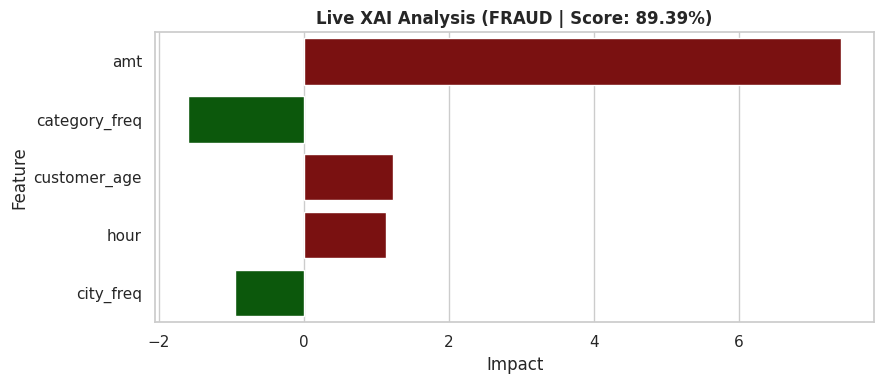


--- LAYER 3: SMART CONTRACT EXECUTION ---
🚨 STATUS: FRAUD DETECTED.
ACTION: Encrypted & Mined to Ledger (Block Hash: fe656db39fcd0a3...)

FINAL TRANSACTION OUTCOME : DENIED
⏱️ TOTAL EXECUTION TIME   : 273.49 milliseconds


In [ ]:
# ==============================================================================
# CELL 5: Blockchain Layer & Final Runtime Completion
# ==============================================================================
AES_KEY = Fernet.generate_key()
cipher_suite = Fernet(AES_KEY)

class Block:
    def __init__(self, index, timestamp, encrypted_data, threat_score, xai_reason, previous_hash):
        self.index = index; self.timestamp = timestamp; self.encrypted_data = encrypted_data
        self.threat_score = threat_score; self.xai_reason = xai_reason; self.previous_hash = previous_hash; self.nonce = 0
        self.hash = self.compute_hash()

    def compute_hash(self):
        block_string = json.dumps({"index": self.index, "timestamp": self.timestamp, "encrypted_data": str(self.encrypted_data), "threat_score": self.threat_score, "xai_reason": self.xai_reason, "previous_hash": self.previous_hash}, sort_keys=True)
        return hashlib.sha256(block_string.encode()).hexdigest()

class SecurityBlockchain:
    def __init__(self):
        self.chain = [Block(0, time.time(), "GENESIS_BLOCK", 0.0, "N/A", "0")]

    def add_fraud_record(self, encrypted_data, threat_score, xai_reason):
        new_block = Block(len(self.chain), time.time(), encrypted_data, threat_score, xai_reason, self.chain[-1].hash)
        self.chain.append(new_block)
        return new_block

fraud_ledger = SecurityBlockchain()

# Uses OPTIMAL_THRESHOLD dynamically discovered in Cell 4
def smart_contract_decision(transaction_dict, ml_probability, start_time, xai_reason, threshold=OPTIMAL_THRESHOLD):
    print("\n--- LAYER 3: SMART CONTRACT EXECUTION ---")
    if ml_probability < threshold:
        print("✅ STATUS: NORMAL (No blockchain entry required).")
        is_approved = True
    else:
        print("🚨 STATUS: FRAUD DETECTED.")
        threat_score = round(ml_probability * 100, 2)
        encrypted_data = cipher_suite.encrypt(json.dumps(str(transaction_dict)).encode('utf-8'))

        new_block = fraud_ledger.add_fraud_record(encrypted_data, threat_score, xai_reason)
        print(f"ACTION: Encrypted & Mined to Ledger (Block Hash: {new_block.hash[:15]}...)")
        is_approved = False

    end_time = time.perf_counter()
    print("\n" + "="*60)
    print(f"FINAL TRANSACTION OUTCOME : {'APPROVED' if is_approved else 'DENIED'}")
    print(f"⏱️ TOTAL EXECUTION TIME   : {(end_time - start_time) * 1000:.2f} milliseconds")
    print("="*60)
    return is_approved

# EXECUTE FULL PIPELINE
result = live_user_input()
if result[0] is not None:
    tx_dict, ml_prob, start_time, xai_reason = result
    smart_contract_decision(tx_dict, ml_prob, start_time, xai_reason)

**Cell 6: Thesis Visualizations & Graphs**

Generating Confusion Matrix...


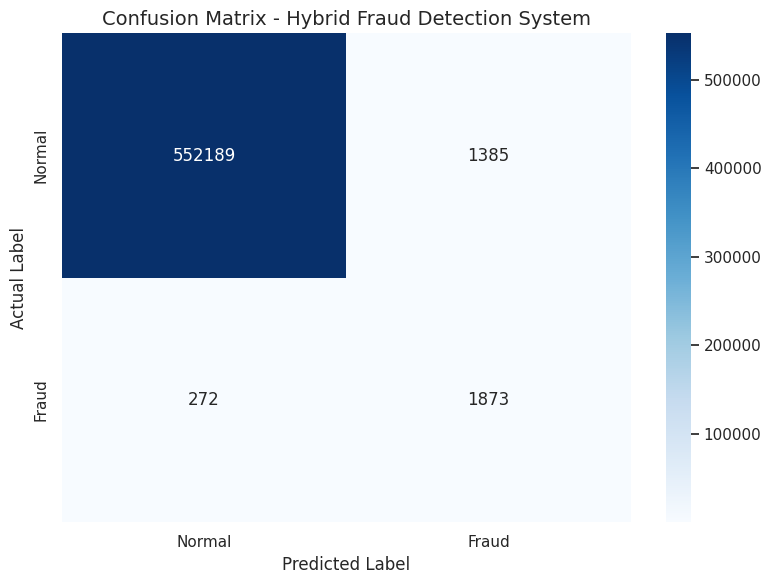


Generating Precision-Recall Curve (AUPRC)...


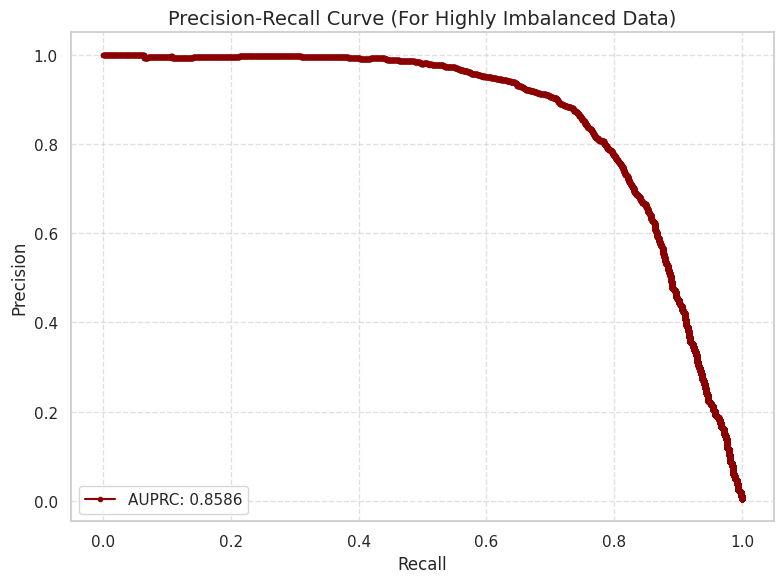


Generating SHAP Summary Plot (This may take a few seconds)...


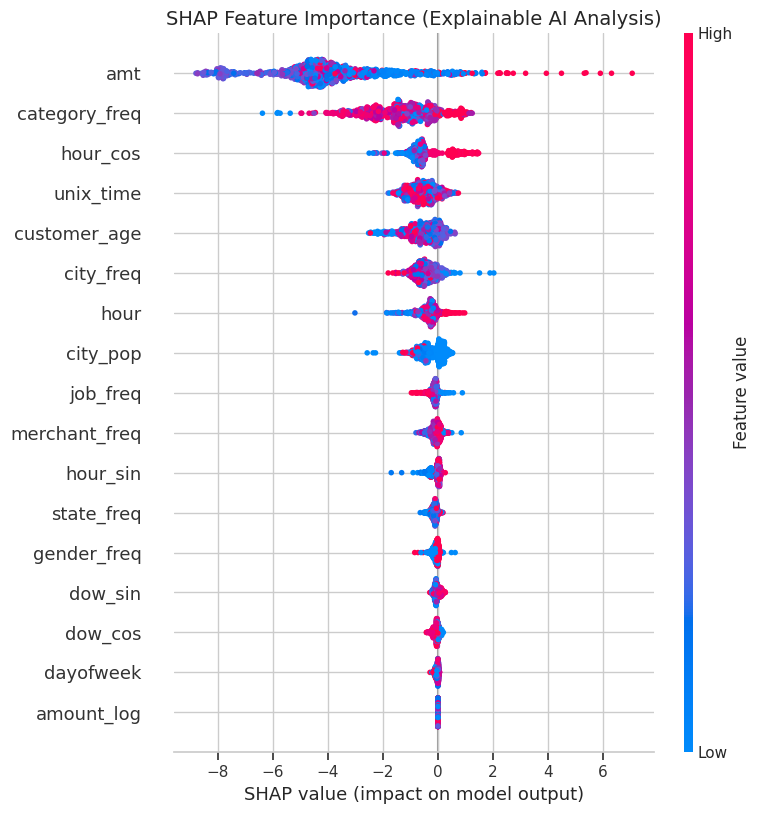

In [ ]:
# ==============================================================================
# CELL 6: Thesis Visualizations & Graphs (Run after Cell 5)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_recall_curve, confusion_matrix, average_precision_score
import shap

# Set general plot style for academic papers
plt.rcParams.update({'font.size': 12, 'axes.titlesize': 14})

# ---------------------------------------------------------
# 1. CONFUSION MATRIX
# ---------------------------------------------------------
print("Generating Confusion Matrix...")
y_pred = ensemble_model.predict(X_test_scaled)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Fraud'],
            yticklabels=['Normal', 'Fraud'])
plt.title('Confusion Matrix - Hybrid Fraud Detection System')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 2. PRECISION-RECALL CURVE (AUPRC)
# ---------------------------------------------------------
print("\nGenerating Precision-Recall Curve (AUPRC)...")
y_pred_proba = ensemble_model.predict_proba(X_test_scaled)[:, 1]
precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
auprc_score = average_precision_score(y_test, y_pred_proba)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, marker='.', color='darkred', label=f'AUPRC: {auprc_score:.4f}')
plt.title('Precision-Recall Curve (For Highly Imbalanced Data)')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend(loc='lower left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 3. SHAP SUMMARY PLOT (EXPLAINABLE AI)
# ---------------------------------------------------------
print("\nGenerating SHAP Summary Plot (This may take a few seconds)...")
# Taking a random sample of 1000 test cases so it generates quickly
shap_sample = X_test_scaled.sample(n=1000, random_state=42)
shap_values_sample = explainer.shap_values(shap_sample)

# Handle different output formats from SHAP based on XGBoost version
if isinstance(shap_values_sample, list):
    shap_values_sample = shap_values_sample[1]

plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values_sample, shap_sample, feature_names=feature_cols, show=False)
plt.title('SHAP Feature Importance (Explainable AI Analysis)')
plt.tight_layout()
plt.show()